In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# 1. Загрузка данных
df = pd.read_csv('data/car_details.csv')
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
df['y'] = df['selling_price']

df['x1_age'] = 2026 - df['year']

df['x2_km_driven'] = df['km_driven']

df['x3_automatic'] = (df['transmission'] == 'Automatic').astype(int)

owner_mapping = {
    'Test Drive Car': 0,
    'First Owner': 1,
    'Second Owner': 2,
    'Third Owner': 3,
    'Fourth & Above Owner': 4
}
df['x4_owners'] = df['owner'].map(owner_mapping)

df['x5_diesel'] = (df['fuel'] == 'Diesel').astype(int)

features = ['y', 'x1_age', 'x2_km_driven', 'x3_automatic', 'x4_owners', 'x5_diesel']

data = df[features].copy()

data.head()

,y,x1_age,x2_km_driven,x3_automatic,x4_owners,x5_diesel
0,60000,19,70000,0,1,0
1,135000,19,50000,0,1,0
2,600000,14,100000,0,1,1
3,250000,9,46000,0,1,0
4,450000,12,141000,0,2,1


In [4]:
corr_matrix_initial = data.corr(method='pearson')
print("Корреляционная матрица (первичная):")
display(corr_matrix_initial.round(3))



Корреляционная матрица (первичная):


,y,x1_age,x2_km_driven,x3_automatic,x4_owners,x5_diesel
y,1.000,-0.414,-0.192,0.530,-0.228,0.283
x1_age,-0.414,1.000,0.420,-0.144,0.469,-0.121
x2_km_driven,-0.192,0.420,1.000,-0.120,0.322,0.285
x3_automatic,0.530,-0.144,-0.120,1.000,-0.083,0.048
x4_owners,-0.228,0.469,0.322,-0.083,1.000,-0.002
x5_diesel,0.283,-0.121,0.285,0.048,-0.002,1.000


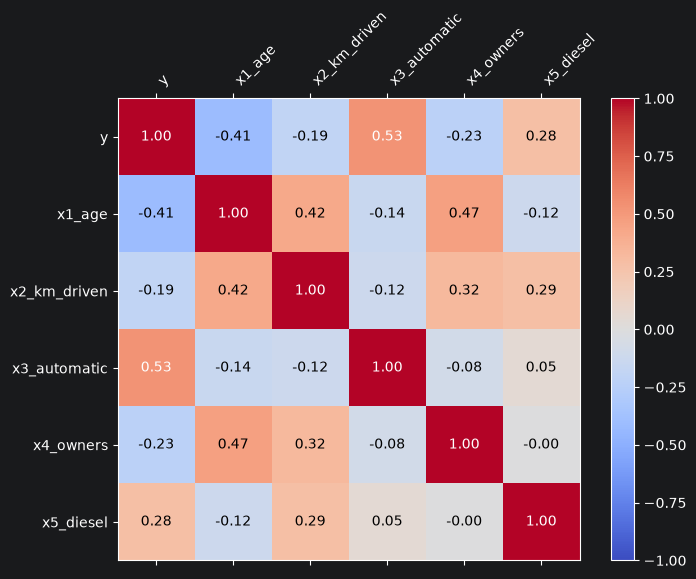

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(corr_matrix_initial, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

ticks = range(len(features))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(features, rotation=45, ha='left')
ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(features)):
        val = corr_matrix_initial.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if abs(val) > 0.5 else 'black')

plt.show()

1. Связь зависимой переменной $y$ с факторами:

   * $r_{y,x_1} \approx -0.414$ — **умеренная обратная связь**: чем старше автомобиль, тем ниже его цена.
   * $r_{y,x_2} \approx -0.192$ — **слабая обратная связь**: с ростом пробега цена снижается, но нелинейно или слабо.
   * $r_{y,x_3} \approx +0.530$ — **заметная прямая связь**: автомобили с автоматической коробкой передач существенно дороже.
   * $r_{y,x_4} \approx -0.228$ — **слабая обратная связь**: большее число владельцев снижает стоимость.
   * $r_{y,x_5} \approx +0.283$ — **слабая прямая связь**: дизельные авто несколько дороже бензиновых.

2. Явная межфакторная мультиколлинеарность в исходных данных отсутствует.

In [12]:
y_corrs = corr_matrix_initial['y'].drop('y')

selected_factors = y_corrs[y_corrs.abs() >= 0.4].index.tolist()

data_filtered = data[['y'] + selected_factors].copy()

Корреляции факторов с y:
x1_age         -0.414
x2_km_driven   -0.192
x3_automatic    0.530
x4_owners      -0.228
x5_diesel       0.283
Name: y, dtype: float64


Корреляционная матрица (после отбора):


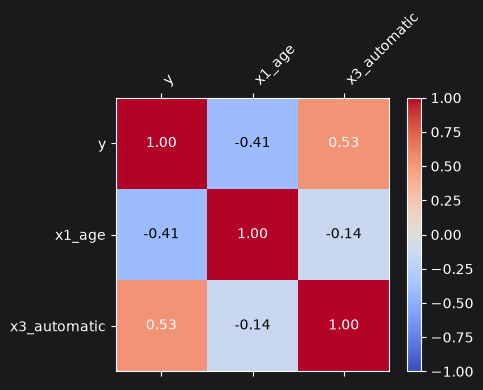

In [14]:
corr_matrix_filtered = data_filtered.corr(method='pearson')
print("Корреляционная матрица (после отбора):")

fig, ax = plt.subplots(figsize=(5, 4))
cax = ax.matshow(corr_matrix_filtered, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

cols = data_filtered.columns
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))

ax.set_xticklabels(cols, rotation=45, ha='left')
ax.set_yticklabels(cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr_matrix_filtered.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if abs(val) > 0.5 else 'black')

plt.tight_layout()
plt.show()

1. **Связь с целевой переменной:**
  * $x_3\text{ (automatic)}$ ($r = +0.530$) — заметная прямая связь, наиболее значимый фактор
  * $x_1\text{ (age)}$ ($r = -0.414$) — умеренная обратная связь
2. **Взаимная корреляция факторов:**
  * $r_{x_1, x_3} \approx -0.144$ — связь между возрастом и типом КПП очень слабая ($|r| < 0.2$). Факторы практически некоррелированы и описывают независимые аспекты стоимости автомобиля.

3. **Отсутствие мультиколлинеарности:**
   Крайне низкая взаимная корреляция между предикторами ($|r_{x_1, x_3}| \approx 0.144 \ll 0.7$) гарантирует отсутствие коллинеарности.
